# Measuring the environemental impacts of deep learning

Constance Douwes - Adapted from Lucia Bouza and Aurélie Bugeau

# Training costs

In this part, we will try to compute the energy consumption of training deep learning models for classification tasks alond with the associated carbon emissions.

## Using Green Algorithms methodology

With green algorithm, the energy consumption is computed as follows:
$$E = T \times \rm{PUE} \times \left(\sum_{c\in {cores}} P_{c}\times \rm{usage}_c + P_{memory} \right) \tag{1}$$
where
- $T$ is the running time in hours
- $\rm{PUE}$ is the Power Usage Effectiveness. It is an efficiency coefficient of the data center.
- $P_{memory}$ is the power consumed by the memory in Watt.
- $cores$ is the set of all CPU and GPU cores
- $P_{c}$ is the power consumed by core $c$ (CPU or GPU) in Watt.
- $\rm{usage}_c$ is the usage factor of core $c$, between $0$ and $1$.


The *carbon footprint* is calculated according to the following formula:

$$CO_2eq = E \times CI \tag{2}$$
where
- $CI$ is the carbon intensity factor of the region where the code is being run

In the following, we will try to find the appropriate information depending on the hardware and infrastructure used.


### CPU

To know the number of available CPUs and the model on the machine where you are running your program, you can execute the following commands.

- **Linux**: `cat /proc/cpuinfo` will display information about the available CPUs. To make the information easy to read, we use the following script that determines the number of configured physical and logical CPUs. You can also use `lscpu`.
- **MacOS**: `sysctl -n machdep.cpu.brand_string` will display Chip Brand, Processor Type, Chip Model and CPU Speed. Detailed info on cpu can further be obtained with the command `sysctl -a | grep machdep.cpu`. Other option can be browsing: **System Settings > General > About > Processor.**
- **Windows**: `wmic cpu get name, numberofcores` will display same information as MacOS command. Other option can be browsing: **Task Manager > Performance > CPU.**

In [ ]:
!cat /proc/cpuinfo | \
awk -v FS=':' '                                       \
  /^physical id/ { if(nb_cpu<$2)  { nb_cpu=$2 } }     \
  /^cpu cores/   { if(nb_cores<$2){ nb_cores=$2 } }   \
  /^processor/   { if(nb_units<$2){ nb_units=$2 } }   \
  /^model name/  { model=$2 }                         \
                                                      \
  END{                                                \
   nb_cpu=(nb_cpu+1);                                 \
   nb_units=(nb_units+1);                             \
                                                      \
   print "CPU model:",model;                          \
   print nb_cpu,"CPU,",nb_cores,"physical cores per CPU, total",nb_units,"logical CPU units" \
 }'

CPU model:  Intel(R) Xeon(R) CPU @ 2.00GHz
1 CPU,  1 physical cores per CPU, total 2 logical CPU units


In [ ]:
!cat /proc/cpuinfo

processor	: 0
vendor_id	: GenuineIntel
cpu family	: 6
model		: 85
model name	: Intel(R) Xeon(R) CPU @ 2.00GHz
stepping	: 3
microcode	: 0xffffffff
cpu MHz		: 2000.172
cache size	: 39424 KB
physical id	: 0
siblings	: 2
core id		: 0
cpu cores	: 1
apicid		: 0
initial apicid	: 0
fpu		: yes
fpu_exception	: yes
cpuid level	: 13
wp		: yes
flags		: fpu vme de pse tsc msr pae mce cx8 apic sep mtrr pge mca cmov pat pse36 clflush mmx fxsr sse sse2 ss ht syscall nx pdpe1gb rdtscp lm constant_tsc rep_good nopl xtopology nonstop_tsc cpuid tsc_known_freq pni pclmulqdq ssse3 fma cx16 pcid sse4_1 sse4_2 x2apic movbe popcnt aes xsave avx f16c rdrand hypervisor lahf_lm abm 3dnowprefetch ssbd ibrs ibpb stibp fsgsbase tsc_adjust bmi1 hle avx2 smep bmi2 erms invpcid rtm mpx avx512f avx512dq rdseed adx smap clflushopt clwb avx512cd avx512bw avx512vl xsaveopt xsavec xgetbv1 xsaves arat md_clear arch_capabilities
bugs		: cpu_meltdown spectre_v1 spectre_v2 spec_store_bypass l1tf mds swapgs taa mmio_stale_data re

### GPU

Knowing the number and model of GPUs, can be done in the following ways:

- **Linux**: `lshw -C display`
- **MacOS**: browse: **System Settings > General > About > Graphics**
- **Windows**: browse: **Task Manager > Performance > GPU**


> Remark: The virtual machine used by Colab does not have some Linux commands. We know that the GPUs used by Colab are Nvidia, so we can use the nvidia-specific command:`!nvidia-smi -L`. This will show the number of available GPUs and their model and UUID.

In [ ]:
!nvidia-smi -L

GPU 0: Tesla T4 (UUID: GPU-3265a525-d1ad-e63e-5e70-3a076ec81944)


### Compute energy from cores

To compute $P_c$ , Green Algorithms use the Thermal Design Power (**TDP**) of the model of the processing unit provided by the manufacturer. A core power usage is assumed to be equal to the TDP divided by the number of cores (if a chip has 2 cores and a TDP of 50W, then the TDP per core is 25).

Use online documentations of CPU and GPU to find TDP values of your CPU and GPU, compute the value of $\sum_{c\in {cores}} P_{c}\times \rm{usage}_c$ in Watt, considering $\rm{usage}_c =1$.

In [1]:
P_GPU = 70#W
P_CPU = 170/12#W
P_cores = P_GPU + P_CPU#W
print(f"Total power cores : {P_cores:.2f}W")

Total power cores : 84.17W


### Memory



We can check the amount of available memory available for the GPU using the following commands:

- **Linux**: `grep MemTotal /proc/meminfo`. The command returns the value in KB. It will be necessary to convert it to GB to use the tool (1 GB = 1024 MB = 1048576 KB). Another command is `free -h --si | awk  '/Mem:/{print $2}'`
- **MacOS**: `system_profiler SPHardwareDataType | grep "Memory:"`. Other option  can be browsing: **System Settings > General > About > Memory.**
- **Windows**: `systeminfo | findstr /C:"Total Physical Memory"`. The command returns the value in MB, it will be necessary to convert it to GB to use the tool. Other option  can be browsing: **Task Manager > Performance > Memory**


Green Algorithms, considers a consumption of 0.3725 W per GB of memory available (if we have all the server memory available, it will account for all the server memory. If we are in an HPC cluster, it will account only for the amount of memory requested, regardless of how much the process consumes). The value 0.3725 was obtained experimentally <a name="cite_ref-2"></a>[[2]](#cite_note-2).

In [ ]:
!grep MemTotal /proc/meminfo

MemTotal:       13286944 kB


In [3]:
Mem_kB = 13286944 #kB
Mem_GB = Mem_kB/1048576 #GB
P_mem = Mem_GB * 0.3725 #W
print(f"Total power memory : {P_mem:.2f} W")

Total power memory : 4.72 W


In [4]:
P_tot = P_mem + P_cores
print(f"Total power : {P_tot:.2f} W")

Total power : 88.89 W


### Location

We can check the execution location with the command:
- **Linux, Windows and MacOS**: `curl ipinfo.io`

> **Remark:** In the case of Colab, you cannot choose where to execute the codes. Nevertheless, you can also use previous command and then determine the datacenter where the code is executed with the following [link](https://cloud.google.com/about/locations?hl=es). We do not know in advance in which datacenter the virtual machine where the notebook will run will be created. It is necessary to execute the command every time we create or reset the runtime, since the location may change.

In [ ]:
!curl ipinfo.io

{
  "ip": "136.67.161.106",
  "hostname": "106.161.67.136.bc.googleusercontent.com",
  "city": "The Dalles",
  "region": "Oregon",
  "country": "US",
  "loc": "45.5946,-121.1787",
  "org": "AS396982 Google LLC",
  "postal": "97058",
  "timezone": "America/Los_Angeles",
  "readme": "https://ipinfo.io/missingauth"
}

Check the carbon intensity factor from this location at : https://app.electricitymaps.com/map/fifteen_minutes

In [41]:
CI = 438 #gC02/kWh

### Time to train a network

In [6]:
import os
import numpy as np
import matplotlib.pyplot as plt
import psutil
import time

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor
from torchsummary import summary


In [7]:
# Load MNIST dataset
train_data = MNIST(root='./data', train=True, transform=ToTensor(), download=True)
test_data = MNIST(root='./data', train=False, transform=ToTensor(), download=True)

train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
test_loader = DataLoader(test_data, batch_size=32, shuffle=False)

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.6MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 461kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.45MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 12.6MB/s]


In [8]:
# Define the model
class Digits(nn.Module):
    def __init__(self):
        super(Digits, self).__init__()
        self.flatten = nn.Flatten(start_dim=1)
        self.hidden_layer = nn.Linear(28*28, 32)
        self.output_layer = nn.Linear(32, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = torch.sigmoid(self.hidden_layer(x))
        x = self.output_layer(x)
        return x


In [9]:
# Define device where to run the training
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
model = Digits().to(device)

In [ ]:
print('Using gpu: %s ' % torch.cuda.is_available())

Using gpu: True 


In [10]:
# Define the loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [11]:
def train(model, nb_epochs):
  for epoch in range(nb_epochs):
      train_loss = 0.0
      train_acc = 0.0
      val_loss = 0.0
      val_acc = 0.0

      model.train()
      for i, (inputs, labels) in enumerate(train_loader):
          inputs, labels = inputs.to(device), labels.to(device)
          optimizer.zero_grad()
          outputs = model(inputs)
          loss = criterion(outputs, labels)
          loss.backward()
          optimizer.step()

          train_loss += loss.item() * inputs.size(0)
          _, preds = torch.max(outputs, 1)
          train_acc += torch.sum(preds == labels.data)

      model.eval()
      with torch.no_grad():
          for i, (inputs, labels) in enumerate(test_loader):
              inputs, labels = inputs.to(device), labels.to(device)
              outputs = model(inputs)
              loss = criterion(outputs, labels)

              val_loss += loss.item() * inputs.size(0)
              _, preds = torch.max(outputs, 1)
              val_acc += torch.sum(preds == labels.data)

      epoch_train_loss = train_loss / len(train_data)
      epoch_train_acc = train_acc / len(train_data)
      epoch_val_loss = val_loss / len(test_data)
      epoch_val_acc = val_acc / len(test_data)

      print('Epoch [{}/{}], Train Loss: {:.4f}, Train Acc: {:.4f}, Val Loss: {:.4f}, Val Acc: {:.4f}'
            .format(epoch+1, nb_epochs, epoch_train_loss, epoch_train_acc, epoch_val_loss, epoch_val_acc))

We will use `time` libreary to measure the time of a piece of code.
More info here : https://docs.python.org/3/library/time.html#time.time


In [12]:
import time
start = time.time()

train(model, 1) #you can change the number of epopchs if needed

stop = time.time()
print('Real Time: {:.4f} seconds'.format(stop-start))

Epoch [1/1], Train Loss: 0.6399, Train Acc: 0.8590, Val Loss: 0.2999, Val Acc: 0.9204
Real Time: 10.9893 seconds


In [35]:
duration_s = 10.5109 # sesconds
duration_h = duration_s/3600 # hours

Watts

In [42]:
Energy = P_tot * duration_h #Wh
CO2e =  Energy/1000 * CI #gCO2
print(f"Energy : {Energy:.2f} Wh")
print(f"Emissions : {CO2e:.2f} gCO2eq")

Energy : 0.26 Wh
Emissions : 0.11 gCO2eq


Compare your results with the online tool Green Algorithm :  https://calculator.green-algorithms.org/


## Using CodeCarbon

In this section, we want to monitor closely the consumption using `codecarbon` library.


In [15]:
import psutil

In [17]:
!pip install codecarbon > /dev/null

There are several ways of using the library, but here we use the recommended way for notebooks, using the `start` and `stop` functions of the tracker. Other options can be found in the [documentation](https://docs.codecarbon.io/latest/tutorials/first-tracking/#step-2-track-emissions-from-a-computation).
 The package by default logs data into a CSV file named `emissions.csv` in the current directory.

### Monitor idle energy consumption

In [44]:
from codecarbon import EmissionsTracker, OfflineEmissionsTracker
# tracker = EmissionsTracker()
tracker = OfflineEmissionsTracker(country_iso_code="USA")

tracker.start()

time.sleep(10)

tracker.stop()

[codecarbon INFO @ 12:21:51] offline tracker init
[codecarbon WARNING @ 12:21:51] Multiple instances of codecarbon are allowed to run at the same time.
[codecarbon INFO @ 12:21:51] Emissions data (if any) will be saved to file /content/emissions.csv
[codecarbon INFO @ 12:21:51] Monitoring GPUs with indices: [0] out of 1 total GPUs
[codecarbon INFO @ 12:21:52] >>> Tracker's metadata:
[codecarbon INFO @ 12:21:52]   Platform system: Linux-6.6.122+-x86_64-with-glibc2.39
[codecarbon INFO @ 12:21:52]   Python version: 3.13.15
[codecarbon INFO @ 12:21:52]   CodeCarbon version: 3.3.1
[codecarbon INFO @ 12:21:52]   Available RAM : 12.671 GB
[codecarbon INFO @ 12:21:52]   CPU count: 2 thread(s) in 1 physical CPU(s)
[codecarbon INFO @ 12:21:52]   CPU model: Intel(R) Xeon(R) CPU @ 2.00GHz
[codecarbon INFO @ 12:21:52]   GPU count: 1
[codecarbon INFO @ 12:21:52]   GPU model: 1 x Tesla T4
[codecarbon INFO @ 12:21:52] Energy consumed for RAM : 0.000000 kWh. RAM Power : 10.0 W
[codecarbon INFO @ 12:21:

4.363788088445634e-05

Using `time.sleep(10)`, mesure the idle consumption of the GPU, whithout doing any compute. What does it corresponds to ?

In [45]:
Energy_idle = tracker.final_emissions_data.energy_consumed * 1000
duration_idle = tracker.final_emissions_data.duration
CO2e_idle = tracker.final_emissions * 1000

print(f"Energy idle : {Energy_idle:.2f} Wh" )
print(f"Duration idle : {duration_idle:.2f} s" )
print(f"Emissions idle : {CO2e_idle:.3f} gCO2eq")

Energy idle : 0.12 Wh
Duration idle : 10.02 s
Emissions idle : 0.044 gCO2eq


In [46]:
P_idle = Energy_idle/(duration_idle/3600) #Watt
print(f"Power idle : {P_idle:.2f} W")

Power idle : 42.42 W


Monitor the emissions from training the digital classifier and compare with the results from green algorithms methodology.

In [47]:
tracker = OfflineEmissionsTracker(country_iso_code="USA")

tracker.start()

train(model, 1)

tracker.stop()

[codecarbon INFO @ 12:22:18] offline tracker init
[codecarbon WARNING @ 12:22:18] Multiple instances of codecarbon are allowed to run at the same time.
[codecarbon INFO @ 12:22:18] Emissions data (if any) will be saved to file /content/emissions.csv
[codecarbon INFO @ 12:22:18] Monitoring GPUs with indices: [0] out of 1 total GPUs
[codecarbon INFO @ 12:22:18] >>> Tracker's metadata:
[codecarbon INFO @ 12:22:18]   Platform system: Linux-6.6.122+-x86_64-with-glibc2.39
[codecarbon INFO @ 12:22:18]   Python version: 3.13.15
[codecarbon INFO @ 12:22:18]   CodeCarbon version: 3.3.1
[codecarbon INFO @ 12:22:18]   Available RAM : 12.671 GB
[codecarbon INFO @ 12:22:18]   CPU count: 2 thread(s) in 1 physical CPU(s)
[codecarbon INFO @ 12:22:18]   CPU model: Intel(R) Xeon(R) CPU @ 2.00GHz
[codecarbon INFO @ 12:22:18]   GPU count: 1
[codecarbon INFO @ 12:22:18]   GPU model: 1 x Tesla T4
[codecarbon INFO @ 12:22:18] Energy consumed for RAM : 0.000000 kWh. RAM Power : 10.0 W
[codecarbon INFO @ 12:22:

Epoch [1/1], Train Loss: 0.2107, Train Acc: 0.9401, Val Loss: 0.1988, Val Acc: 0.9413


4.608832822125942e-05

In [48]:
Energy_train = tracker.final_emissions_data.energy_consumed * 1000
duration_train = tracker.final_emissions_data.duration
CO2e_train = tracker.final_emissions * 1000

print(f"Energy train : {Energy_train:.2f} Wh" )
print(f"Duration train : {duration_train:.2f} s" )
print(f"Emissions train : {CO2e_train:.3f} gCO2e")

Energy train : 0.12 Wh
Duration train : 10.29 s
Emissions train : 0.046 gCO2e


In [49]:
P_train = Energy_train/(duration_train/3600)
print(f"Power train : {P_train:.2f} W")

Power train : 43.66 W


# Inference costs


In this section, we want to calculate the energy cost of inference. We will use pretrained models from torchvision available at https://docs.pytorch.org/vision/stable/models.html


Load several models from torchvision.

In [77]:
from torchvision.models import resnet50, inception_v3, vit_b_16

models = [
    ("resnet50",     resnet50,     224),
    ("inception_v3", inception_v3, 299),
    ("vit_b_16",     vit_b_16,     224),
]

Monitor the consumption of a 1000 forwards pass for each model using different sizes of batch, and compare with the performance.

In [78]:
for name, model, input_size in models:
    model = model(weights="DEFAULT").to(device).eval()
    x = torch.randn(32, 3, input_size, input_size, device=device)

    tracker = OfflineEmissionsTracker(country_iso_code="USA")
    tracker.start()

    model.eval()
    with torch.no_grad():
        for i in range(100): #100 inferences
          model(x)

    tracker.stop()

    print("")
    print(f"{name}")
    Energy_inf = tracker.final_emissions_data.energy_consumed * 1000
    duration_inf = tracker.final_emissions_data.duration
    CO2e_inf = tracker.final_emissions * 1000
    P_inf = Energy_inf/(duration_inf/3600)

    print(f"Energy inf : {Energy_inf:.2f} Wh" )
    print(f"Duration inf : {duration_inf:.2f} s" )
    print(f"Emissions inf : {CO2e_inf:.2f} gCO2eq")
    print(f"Power inf : {P_inf:.2f} W")
    print("")


[codecarbon INFO @ 12:33:25] offline tracker init
[codecarbon WARNING @ 12:33:25] Multiple instances of codecarbon are allowed to run at the same time.
[codecarbon INFO @ 12:33:25] Emissions data (if any) will be saved to file /content/emissions.csv
[codecarbon INFO @ 12:33:25] Monitoring GPUs with indices: [0] out of 1 total GPUs
[codecarbon INFO @ 12:33:25] >>> Tracker's metadata:
[codecarbon INFO @ 12:33:25]   Platform system: Linux-6.6.122+-x86_64-with-glibc2.39
[codecarbon INFO @ 12:33:25]   Python version: 3.13.15
[codecarbon INFO @ 12:33:25]   CodeCarbon version: 3.3.1
[codecarbon INFO @ 12:33:25]   Available RAM : 12.671 GB
[codecarbon INFO @ 12:33:25]   CPU count: 2 thread(s) in 1 physical CPU(s)
[codecarbon INFO @ 12:33:25]   CPU model: Intel(R) Xeon(R) CPU @ 2.00GHz
[codecarbon INFO @ 12:33:25]   GPU count: 1
[codecarbon INFO @ 12:33:25]   GPU model: 1 x Tesla T4
[codecarbon INFO @ 12:33:25] Energy consumed for RAM : 0.000000 kWh. RAM Power : 10.0 W
[codecarbon INFO @ 12:33:


resnet50
Energy inf : 0.21 Wh
Duration inf : 9.26 s
Emissions inf : 0.08 gCO2eq
Power inf : 79.92 W



[codecarbon INFO @ 12:33:34] offline tracker init
[codecarbon WARNING @ 12:33:34] Multiple instances of codecarbon are allowed to run at the same time.
[codecarbon INFO @ 12:33:34] Emissions data (if any) will be saved to file /content/emissions.csv
[codecarbon INFO @ 12:33:34] Monitoring GPUs with indices: [0] out of 1 total GPUs
[codecarbon INFO @ 12:33:34] >>> Tracker's metadata:
[codecarbon INFO @ 12:33:34]   Platform system: Linux-6.6.122+-x86_64-with-glibc2.39
[codecarbon INFO @ 12:33:34]   Python version: 3.13.15
[codecarbon INFO @ 12:33:34]   CodeCarbon version: 3.3.1
[codecarbon INFO @ 12:33:35]   Available RAM : 12.671 GB
[codecarbon INFO @ 12:33:35]   CPU count: 2 thread(s) in 1 physical CPU(s)
[codecarbon INFO @ 12:33:35]   CPU model: Intel(R) Xeon(R) CPU @ 2.00GHz
[codecarbon INFO @ 12:33:35]   GPU count: 1
[codecarbon INFO @ 12:33:35]   GPU model: 1 x Tesla T4
[codecarbon INFO @ 12:33:35] Energy consumed for RAM : 0.000000 kWh. RAM Power : 10.0 W
[codecarbon INFO @ 12:33:


inception_v3
Energy inf : 0.27 Wh
Duration inf : 12.19 s
Emissions inf : 0.10 gCO2eq
Power inf : 79.89 W



[codecarbon INFO @ 12:33:48] offline tracker init
[codecarbon WARNING @ 12:33:48] Multiple instances of codecarbon are allowed to run at the same time.
[codecarbon INFO @ 12:33:48] Emissions data (if any) will be saved to file /content/emissions.csv
[codecarbon INFO @ 12:33:48] Monitoring GPUs with indices: [0] out of 1 total GPUs
[codecarbon INFO @ 12:33:48] >>> Tracker's metadata:
[codecarbon INFO @ 12:33:48]   Platform system: Linux-6.6.122+-x86_64-with-glibc2.39
[codecarbon INFO @ 12:33:48]   Python version: 3.13.15
[codecarbon INFO @ 12:33:48]   CodeCarbon version: 3.3.1
[codecarbon INFO @ 12:33:48]   Available RAM : 12.671 GB
[codecarbon INFO @ 12:33:48]   CPU count: 2 thread(s) in 1 physical CPU(s)
[codecarbon INFO @ 12:33:48]   CPU model: Intel(R) Xeon(R) CPU @ 2.00GHz
[codecarbon INFO @ 12:33:48]   GPU count: 1
[codecarbon INFO @ 12:33:48]   GPU model: 1 x Tesla T4
[codecarbon INFO @ 12:33:48] Energy consumed for RAM : 0.000000 kWh. RAM Power : 10.0 W
[codecarbon INFO @ 12:33:


vit_b_16
Energy inf : 0.68 Wh
Duration inf : 30.41 s
Emissions inf : 0.25 gCO2eq
Power inf : 80.14 W



At this point, you can test the influence of the batch size

## Hardware independant metrics

We will use `thop`library to count the number of parameters and operations of a model. All the documentation is available here : https://github.com/Lyken17/pytorch-OpCounter

In [80]:
!pip install thop > /dev/null

In [82]:
from thop import profile

In [84]:
for name, model, size in models:
  model = model(weights="DEFAULT").to(device).eval()
  x = torch.randn(32, 3, size, size, device=device)

  macs, params = profile(model, inputs=(x, ))
  macs, params = clever_format([macs, params], "%.2f")

  print("")
  print(f"{name}")
  print(f"Number of MACs : {macs}")
  print(f"Number of parameters : {params}")
  print("")

[INFO] Register count_convNd() for <class 'torch.nn.modules.conv.Conv2d'>.
[INFO] Register count_normalization() for <class 'torch.nn.modules.batchnorm.BatchNorm2d'>.
[INFO] Register zero_ops() for <class 'torch.nn.modules.activation.ReLU'>.
[INFO] Register zero_ops() for <class 'torch.nn.modules.pooling.MaxPool2d'>.
[INFO] Register zero_ops() for <class 'torch.nn.modules.container.Sequential'>.
[INFO] Register count_adap_avgpool() for <class 'torch.nn.modules.pooling.AdaptiveAvgPool2d'>.
[INFO] Register count_linear() for <class 'torch.nn.modules.linear.Linear'>.

resnet50
Number of MACs : 132.28G
Number of parameters : 25.56M

[INFO] Register count_convNd() for <class 'torch.nn.modules.conv.Conv2d'>.
[INFO] Register count_normalization() for <class 'torch.nn.modules.batchnorm.BatchNorm2d'>.
[INFO] Register zero_ops() for <class 'torch.nn.modules.pooling.MaxPool2d'>.
[INFO] Register count_linear() for <class 'torch.nn.modules.linear.Linear'>.
[INFO] Register count_adap_avgpool() for <

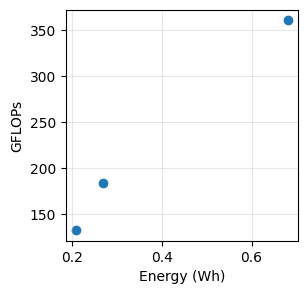

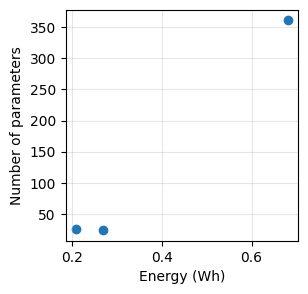

In [94]:
models = ['resnet', 'inception_v3', 'vit_b_16']
energy = [0.21, 0.27, 0.68]
macs =  [132.28, 183.98,361.16]
params = [25.56,23.83,361.16]

# FLOPs vs Duration
plt.figure(figsize=(3,3))
plt.scatter(energy, macs)
plt.xlabel('Energy (Wh)')
plt.ylabel('GFLOPs')
plt.grid(True, alpha=0.3)

# Number of parameters vs Duration
plt.figure(figsize=(3,3))
plt.scatter(energy, params)
plt.xlabel('Energy (Wh)')
plt.ylabel('Number of parameters')
plt.grid(True, alpha=0.3)


# Prompting with your best-LLMs-friends :)

Let’s estimate your energy consumption and carbon footprint of using LLMs last week using
https://calculator.ecologits.ai/

You can download your history
https://help.openai.com/en/articles/7260999-exporting-your-chatgpt-history-and-data?utm_source=chatgpt.com



Location of the datacenter :
https://docs.google.com/spreadsheets/d/1XkPTkrGxpwWpIVIxpVvgRJuInSZsqbndTQbFGcHhdd0/edit?gid=122417664#gid=122417664

| AI Provider | Cloud Provider | Location | PUE | WUE (L/kWh) |
| --- | --- | :-: | :-: | :-: |
| Anthropic | AWS, Google | USA | 1.09 – 1.14 | 0.13 – 1.00 |
| Cohere | Google | USA | 1.09 | 1.00 |
| Google | Google | USA  | 1.09 | 1.00 |
| Hugging Face | AWS, Google | USA | 1.09 – 1.14 | 0.13 – 1.00 |
| Mistral AI | Microsoft | SWE | 1.16 | 0.09 |
| OpenAI | Microsoft | USA | 1.20 | 0.569 |
| Azure OpenAI | Microsoft | USA | 1.20 | 0.569 |

In [95]:
prompts_per_day = 20
energy_prompt = 7.46 #Wh
CI = 460 #US

Energy_prompt_year = prompts_per_day * 365 * energy_prompt #Wh
CO2e_prompt_year = Energy_prompt_year/1000 * CI #gCO2

print(f"Energy LLM per year: {Energy_prompt_year:.0f} Wh")
print(f"Emissions LLM per year : {CO2e_prompt_year/1000:.2f} kgCO2eq")

Energy LLM per year: 54458 Wh
Emissions LLM per year : 25.05 kgCO2eq


Compare this with your consumption with video streaming (Insta / TV / Netflix)
https://impactco2.fr/outils/usagenumerique/streamingvideo

In [96]:
CO2e_streaming = 28.6 * 365

In [98]:
print(f"Emissions Streaming per year: {CO2e_streaming/1000} gCO2e")

Emissions Streaming per year: 10.439 gCO2e


Considering that there are 2,5 billions of prompts everyday on ChatGPT, try to estimate the impact per year.


In [107]:
prompts_chatGPT_all = 2.5 * 1000000000 * 365 #Wh
Energy_chatGPT_all = 10 #Wh
CO2_chatGPT_all = Energy_chatGPT_all/1000 * prompts_chatGPT_all * 460# gC02

In [112]:
print(f"Emissions chatGPT all users, per year: {CO2_chatGPT_all / 1000000:.0f} tCO2 so, {CO2_chatGPT_all / 1000000:.0f} " )

Emissions chatGPT all users, per year: 4197500 tCO2
